# Loop Splendor Scores

We generate plots of the loop-level splendor score:
- an overview map of the main specification (as defined in [src/splendor/config.py](../../src/splendor/config.py))
- close-ups of the highest- and lowest-ranked loops

To do this, we read the output from [scripts/loops/compute_score.py](../../scripts/loops/compute_score.py).

<br><br>

## 0. Setup

### 0.1. Imports and Config

In [1]:
import numpy as np
import pandas as pd

from splendor.config import STUDY_AREA, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS, MAIN_SPECIFICATION
from splendor.io import load_network
from splendor.loops.census import LoopData
from splendor.loops.attributes import node_max, edge_max
from splendor.loops.selection import select_distinct_loops
from splendor.paths import network_path, loop_census_path, splendor_path
from splendor.plotting.scores import plot_link_maps, plot_node_maps

from splendor.config import TOP_SHARE, COMPONENT_WEIGHTS, REFERENCE_WEIGHTS
from splendor.io import load_raster, load_rank_correlations
from splendor.loops.geometry import get_loop_lines, get_loop_corridors
from splendor.paths import (
    basemap05_main_types_path,
    landuse_path,
    components_path,
    loop_attributes_path,
    landuse_plot_path,
    ensure_parent,
    score_grid_path,
    rank_summary_path,
    rank_correlations_path
)
from splendor.plotting.landuse import plot_landuse_grid
from splendor.composite.sensitivity import COMBINATION_COLUMNS, WEIGHT_COLUMNS, summarize_correlations

N_CLOSE_UPS = 4 # Loops per top/bottom grid

MAX_OVERLAP = .5 # Close-ups show loops sharing at most half their length with a better-ranked shown loop

LEVEL = "loops"
PATH_ARGS = (STUDY_AREA, LEVEL, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS)
PERCENTILE_LABEL = "Percentile of best loop (100 = best)"

weight_label = lambda weights: "/".join(f"{w:.2g}" for w in weights) # (0.6, 0.2, 0.2) -> "0.6/0.2/0.2"

### 0.2. Data

In [2]:
nodes, edges = load_network(network_path(STUDY_AREA))
loops = LoopData.load(loop_census_path(STUDY_AREA))
splendor = pd.read_csv(splendor_path(*PATH_ARGS), index_col="loop_id")

# Node and edge ids must be the positions used in the loop data
assert (nodes["node_id"].to_numpy() == np.arange(len(nodes))).all(), "nodes not in node_id order"
assert (edges["edge_id"].to_numpy() == np.arange(len(edges))).all(), "edges not in edge_id order"
assert (splendor.index.to_numpy() == np.arange(loops.n_loops)).all(), "splendor scores don't match the census"

# Each loop's position in the ranking, 100 = best loop, 0 = worst
splendor["percentile"] = 100 * (1 - (splendor["rank"] - 1) / (loops.n_loops - 1))

In [3]:
# For the close-ups
raster, transform, _ = load_raster(basemap05_main_types_path(STUDY_AREA))
shares = pd.read_csv(landuse_path(*PATH_ARGS), index_col="loop_id")
components = pd.read_csv(components_path(*PATH_ARGS), index_col="loop_id")
attributes = pd.read_csv(loop_attributes_path(STUDY_AREA), index_col="loop_id")

In [4]:
grid = pd.read_csv(score_grid_path(*PATH_ARGS))
summary = pd.read_csv(rank_summary_path(*PATH_ARGS))
correlations = load_rank_correlations(rank_correlations_path(*PATH_ARGS), COMBINATION_COLUMNS)

<br><br>

## 1. Overview Map

Main specification: measure shannon, normalization zscore, aggregation mean, land_use_weight 0.5, poi_weight 0.25, attractiveness_weight 0.25
On no loop: 0 nodes, 2 links


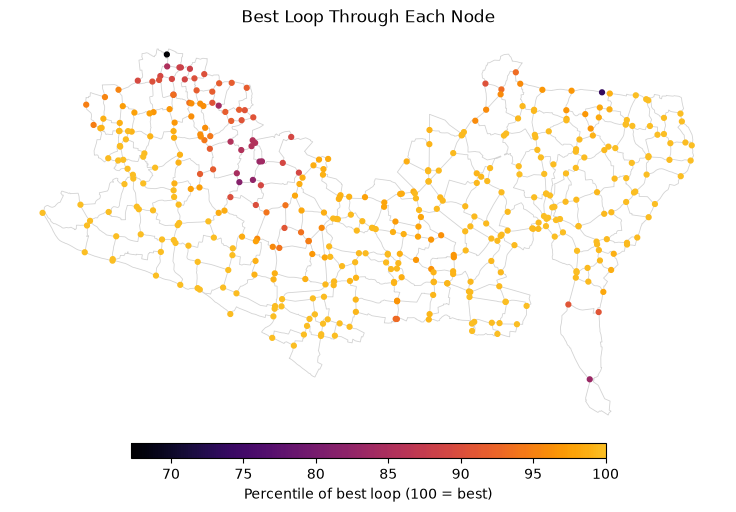

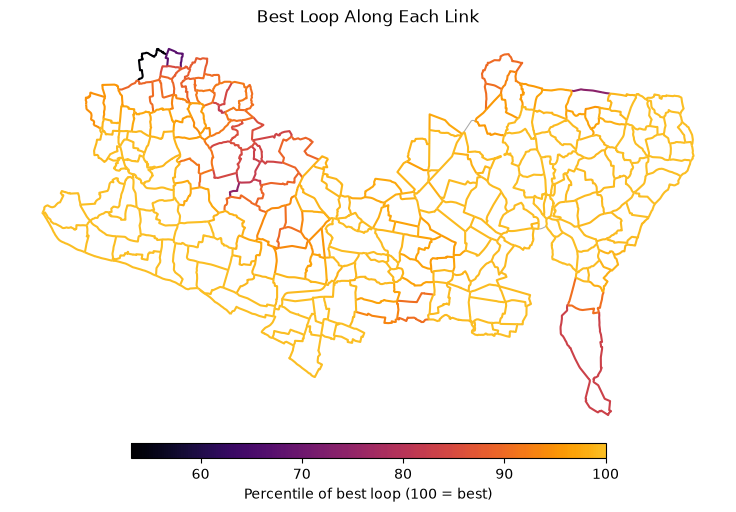

In [5]:
spec = ", ".join(f"{k} {v}" for k, v in MAIN_SPECIFICATION.items())
print("Main specification:", spec)

percentiles = splendor["percentile"].to_numpy()
best_by_node = pd.DataFrame({"node_id": nodes["node_id"], "best_percentile": node_max(loops, percentiles)})
best_by_link = pd.DataFrame({"edge_id": edges["edge_id"], "best_percentile": edge_max(loops, percentiles)})
print(f"On no loop: {best_by_node['best_percentile'].isna().sum()} nodes, {best_by_link['best_percentile'].isna().sum()} links")

plot_node_maps(
    nodes, edges, best_by_node, ["best_percentile"],
    ["Best Loop Through Each Node"], [PERCENTILE_LABEL], panel_size=(8, 5)
);
plot_link_maps(
    edges, best_by_link, ["best_percentile"],
    ["Best Loop Along Each Link"], [PERCENTILE_LABEL], panel_size=(8, 5), allow_missing=True
);

<br><br>

## 2. Top and Bottom Loops

Saved /Users/sanderengelthilo/dev/bikenwsplendor/plots/pilot/loop_landuse_top_r100.png
Saved /Users/sanderengelthilo/dev/bikenwsplendor/plots/pilot/loop_landuse_bottom_r100.png


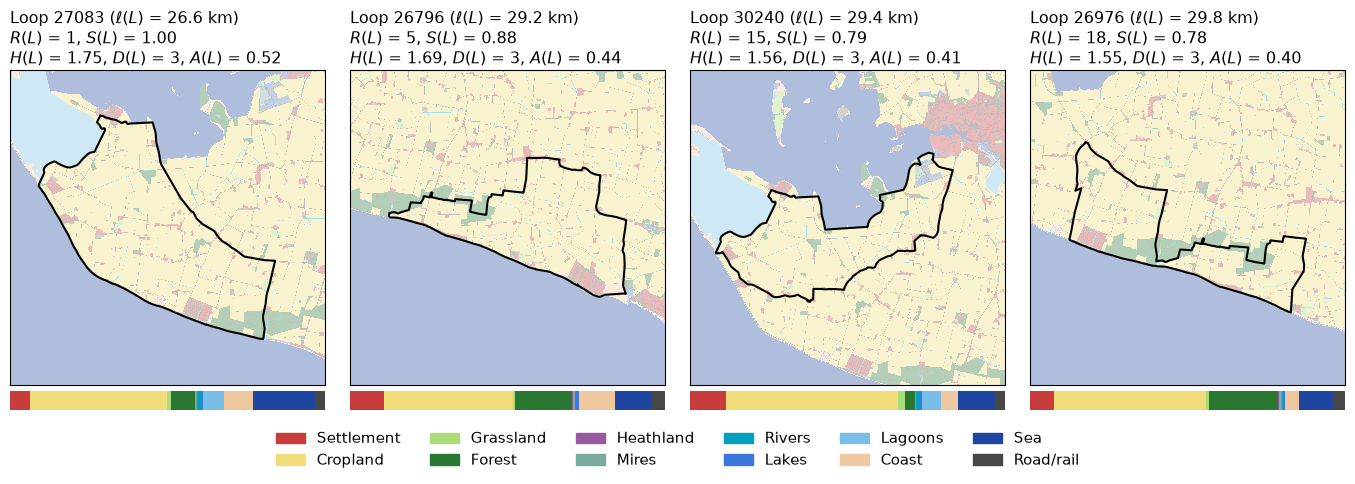

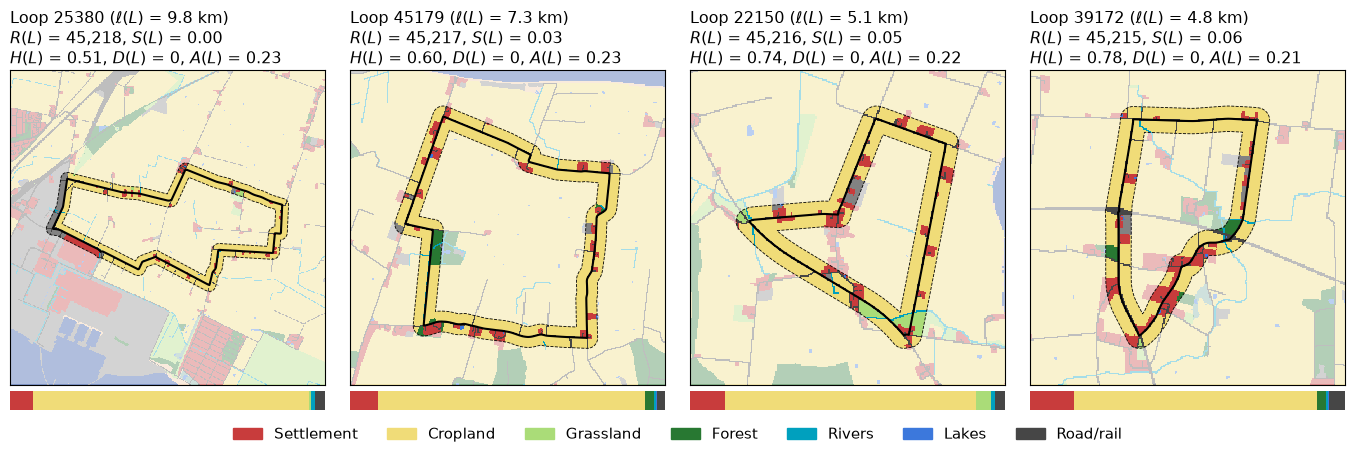

In [6]:
details = (
    splendor["rank"].map(lambda r: f"$R(L)$ = {int(r):,}")
    + splendor["score"].map(lambda s: f", $S(L)$ = {s:.2f}")
    + components["diversity_shannon"].map(lambda h: f"\n$H(L)$ = {h:.2f}")
    + attributes["poi_diversity"].map(lambda p: f", $D(L)$ = {p}")
    + components["attractiveness"].map(lambda a: f", $A(L)$ = {a:.2f}")
)

edge_lengths = edges["length_m"].to_numpy()
by_rank = splendor.sort_values("rank").index.to_numpy()
top = select_distinct_loops(loops, edge_lengths, by_rank, N_CLOSE_UPS, MAX_OVERLAP)
bottom = select_distinct_loops(loops, edge_lengths, by_rank[::-1], N_CLOSE_UPS, MAX_OVERLAP)

for loop_ids, label in [(top, "Top"), (bottom, "Bottom")]:
    lines = get_loop_lines(loops, edges, loop_ids)
    corridors = get_loop_corridors(loops, edges, loop_ids, CORRIDOR_RADIUS)
    fig = plot_landuse_grid(
        loop_ids, lines, corridors, shares, raster, transform,
        details=details, unit="Loop", symbol="L", fontsize=11.5, show_pixels=False
        # title=f"{label} {N_CLOSE_UPS} Loops (≤{MAX_OVERLAP:.0%} Overlap) by Splendor Score",
    )
    OUT = landuse_plot_path(STUDY_AREA, LEVEL, CORRIDOR_RADIUS, label.lower())
    fig.savefig(ensure_parent(OUT), dpi=150)
    print(f"Saved {OUT}")

In [7]:
# Top attractiveness loop (to confirm that it's 27083)
attractiveness = components["attractiveness"]
print(f"Max A(L): {attractiveness.max():.4f} (loop {attractiveness.idxmax()})")
print(f"Loop 27083: {attractiveness.loc[27083]:.4f}")

Max A(L): 0.5247 (loop 27083)
Loop 27083: 0.5247


<br><br>

## 3. Rank Sensitivity

In [8]:
n = len(summary)
top_loops = summary.nsmallest(int(np.ceil(TOP_SHARE * n)), "median_rank")
print(f"Median rank IQR as share of the {n} loops: "
      f"top {TOP_SHARE:.0%} ({len(top_loops)} loops) {top_loops['iqr_rank'].median() / n:.1%}, "
      f"all {summary['iqr_rank'].median() / n:.1%}")

print(summarize_correlations(correlations, COMPONENT_WEIGHTS).round(3))

Median rank IQR as share of the 45218 loops: top 5% (2261 loops) 2.6%, all 13.2%
                    count    min  median    max
all pairs           496.0  0.517   0.813  1.000
only measure         16.0  0.703   0.767  0.866
only normalization   48.0  0.795   0.958  0.998
only weights         48.0  0.907   0.993  1.000


<br><br>

## 4. Reference Rankings

In [9]:
same = grid
for column in ("measure", "normalization", "aggregation"):
    same = same[same[column] == MAIN_SPECIFICATION[column]]

order = [weight_label(w) for w in (*COMPONENT_WEIGHTS, *REFERENCE_WEIGHTS)]
same = same.assign(weights=same[WEIGHT_COLUMNS].apply(weight_label, axis=1))
ranks_by_weight = same.pivot(index="loop_id", columns="weights", values="rank")[order]
print(ranks_by_weight.corr(method="spearman").round(2))

weights         0.5/0.25/0.25  0.6/0.2/0.2  0.4/0.3/0.3  0.33/0.33/0.33  \
weights                                                                   
0.5/0.25/0.25            1.00         0.99         0.99            0.97   
0.6/0.2/0.2              0.99         1.00         0.96            0.93   
0.4/0.3/0.3              0.99         0.96         1.00            0.99   
0.33/0.33/0.33           0.97         0.93         0.99            1.00   
1/0/0                    0.91         0.95         0.84            0.77   
0/1/0                    0.47         0.44         0.49            0.50   
0/0/1                    0.41         0.33         0.50            0.57   

weights         1/0/0  0/1/0  0/0/1  
weights                              
0.5/0.25/0.25    0.91   0.47   0.41  
0.6/0.2/0.2      0.95   0.44   0.33  
0.4/0.3/0.3      0.84   0.49   0.50  
0.33/0.33/0.33   0.77   0.50   0.57  
1/0/0            1.00   0.31   0.14  
0/1/0            0.31   1.00  -0.09  
0/0/1            0.1

<br><br>

## 5. Conclusion

**Overview maps**

Almost every node and link has a best loop in the top 5%. Each lies on many loops, and the best of them is nearly always a high-ranked one. The maps therefore mainly show where options are limited: the north-west, the southern tip of Falster and a few nodes and links at the edges of the network (down to about the 55th–70th percentile). Two links lie on no loop. A best-loop map says little about the typical loop, and a per-node mean or median would show more variation.

**Top loops**

The top 8 are variants of one route along the same stretch of coast, several sharing most of their links. They combine cropland (41–50%) with sea (12–20%), coast and forest, have the highest attractiveness in the census (0.44–0.52, maximum is loop 27083 with 0.525), and all but one have all three POI categories.

**Bottom loops**

The lowest-ranked loops are nearly pure cropland (77–88%) with settlement. The bottom four are short (5–10 km) and have no POI categories, and the next four have one. POI decides the bottom: missing categories push loops below any land use differences. Short loops collect there, even though length barely correlates with the score overall.